this script compares the scientific workforce of countries in international collaboration and domestically. the way of testing it is to bootstrapping researchers from each country and compare the expected results with the actual international workforce.

In [1]:
import pandas as pd
from time import time
import numpy as np
import tqdm
import geopandas as gp
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
import seaborn as sns
import itertools
from matplotlib.lines import Line2D

In [2]:
pub_detail_path='../../data/dropbox/LaborDivision/Data/deriveddata/pub_detail.pkl'
author_path='../../data/dropbox/LaborDivision/Data/deriveddata/authors_ordered.pkl'
author_info_path='../../data/dropbox/LaborDivision/Data/cleanedraw/author_info.pkl'
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_classification/cntry_group_meta.csv'

In [3]:
output_path='../../data/dropbox/LaborDivision/Data/deriveddata/national_bootstrapping/national_boostrappting.csv'
plot_path='../../data/dropbox/LaborDivision/figs/national_comparision.pdf'

In [4]:
pub_all=pd.read_pickle(pub_detail_path)

In [5]:
pub_all.head()

,id,year,dis,alpha,teamsize,int
0,38579295,2012,1,no,4,0
1,38579296,2012,120,no,4,0
2,38579297,2012,84,no,4,1
3,38579302,2012,55,no,4,0
4,38579305,2012,43,no,4,0


In [6]:
pub_int=pub_all[pub_all.int==1]
pub_int.head()

,id,year,dis,alpha,teamsize,int
2,38579297,2012,84,no,4,1
14,38579353,2012,132,no,3,1
22,38579379,2012,51,yes,2,1
27,38579408,2012,33,no,4,1
28,38579409,2012,12,no,4,1


In [7]:
author_all=pd.read_pickle(author_path)
author_all.head()

,id,year,dis,cluster_id,role,Code
0,29768068,2008,56,1306275,F,CAN
1,29768068,2008,56,1680670,M,CAN
2,29768068,2008,56,28261869,L,CAN
3,29768070,2008,51,20009795,F,JPN
4,29768070,2008,51,29411586,M,JPN


In [8]:
author_info=pd.read_pickle(author_info_path)
author_info.head()

,cluster_id,yfp,npub,gender
0,689940,2008,1,unk
1,44823147,2008,1,unk
2,27676457,2011,1,M
3,59751143,2018,1,F
4,59894652,2004,8,M


### select international authors and domestic authors

In [9]:
author_all = author_all.merge(pub_all[['id','int']], on=['id'])
# remove duplicated cases that author record are unique in year, cntry and collobarion
author_all = author_all[['cluster_id','year','Code','int']].drop_duplicates()
# select the international authors
author_int = author_all[author_all.int==1]
# select domestic authors
author_int_or_dome = author_all.drop_duplicates(subset=['cluster_id','year','Code'],keep=False)
author_dome = author_int_or_dome[author_int_or_dome.int==0]

IOStream.flush timed out


In [10]:
author_int_info = author_int.merge(author_info, on='cluster_id')
author_dome_info = author_dome.merge(author_info, on='cluster_id')

In [11]:
years=author_all.year.unique()
cntrys=author_all.Code.unique()

In [12]:
def return_authors(df,cntry,year):
    return df[(df.year==year)&(df['Code']==cntry)]

In [13]:
def return_measurement(df):
    #return the median age of first publication year, median number of publication, number of Male and number of Female
    yfp=df['yfp'].median()
    npub=df['npub'].median()
    try:
        male=df['gender'].value_counts()['M']
    except KeyError:
        male=0
    try:
        female=df['gender'].value_counts()['F']
    except KeyError:
        female=0
    return yfp, npub, male, female

In [14]:
def return_sample(df,sample_size):
    return df.sample(n=sample_size, replace=True)

In [15]:
result=[]
for year,cntry in tqdm.tqdm(itertools.product(years,cntrys),total=len(years)*len(cntrys)):
    int_author=return_authors(author_int_info,cntry,year)
    dom_author=return_authors(author_dome_info,cntry,year)
    
    if len(dom_author)>0 and len(int_author)>0:

        yfp_raw,npub_raw,male_raw,female_raw=return_measurement(int_author)
        result.append([cntry,year,'raw',yfp_raw,npub_raw,male_raw,female_raw])

        sample_size=int_author.shape[0]
        for i in range(10):
            sample_df=return_sample(dom_author,sample_size)
            yfp_s,npub_s,male_s,female_s=return_measurement(sample_df)
            result.append([cntry,year,'sample',yfp_s,npub_s,male_s,female_s])
    else:
        result.append([cntry,year,'invalid'])

100%|█████████████████████████████████████████████████████████████████████████| 2626/2626 [2:19:05<00:00,  3.18s/it]


In [16]:
pd.DataFrame(result,columns=['cntry','year','source','yfp','npub','male','female']
            ).to_csv(output_path,index=False)

In [17]:
boot_df=pd.read_csv(output_path)

In [18]:
boot_df

,cntry,year,source,yfp,npub,male,female
0,CAN,2008,raw,2002.0,14.0,14219.0,6708.0
1,CAN,2008,sample,2006.0,4.0,13221.0,8691.0
2,CAN,2008,sample,2006.0,4.0,13198.0,8727.0
3,CAN,2008,sample,2006.0,4.0,13137.0,8693.0
4,CAN,2008,sample,2006.0,4.0,13086.0,8719.0
...,...,...,...,...,...,...,...
25101,FRO,2020,sample,2020.0,2.0,6.0,10.0
25102,FRO,2020,sample,2020.0,1.0,9.0,4.0
25103,FRO,2020,sample,2020.0,1.0,10.0,8.0
25104,FRO,2020,sample,2020.0,1.0,5.0,4.0


In [19]:
agg_df=boot_df.groupby(['cntry','year','source']).agg({'yfp':'mean',
                                                      'npub':'mean',
                                                      'male':'mean',
                                                      'female':'mean'}).reset_index()

In [20]:
agg_df=agg_df.dropna()
agg_df = agg_df.pivot(index=['cntry','year'],columns='source').reset_index()

In [21]:
agg_df.columns=agg_df.columns.map('_'.join)

In [22]:
agg_df

,cntry_,year_,yfp_raw,yfp_sample,npub_raw,npub_sample,male_raw,male_sample,female_raw,female_sample
0,ABW,2019,2017.5,2018.5,2.5,3.5,3.0,6.0,2.0,0.0
1,AFG,2008,2008.0,2008.0,3.0,1.0,26.0,22.7,2.0,0.0
2,AFG,2009,2009.0,2009.0,2.5,1.0,13.0,24.9,6.0,0.0
3,AFG,2010,2010.0,2010.0,1.0,1.0,20.0,20.9,4.0,10.1
4,AFG,2011,2011.0,2011.0,1.5,1.0,26.0,26.8,5.0,13.2
...,...,...,...,...,...,...,...,...,...,...
2243,ZWE,2016,2013.0,2015.4,6.0,2.5,180.0,194.7,127.0,96.7
2244,ZWE,2017,2014.0,2016.6,6.0,2.5,225.0,224.8,139.0,105.6
2245,ZWE,2018,2016.0,2018.0,4.0,1.9,251.0,270.6,153.0,128.3
2246,ZWE,2019,2016.5,2018.7,3.0,2.0,260.0,294.0,175.0,120.0


In [23]:
agg_df['year_diff']=agg_df['yfp_raw']-agg_df['yfp_sample']
agg_df['npub_diff']=(agg_df['npub_raw']-agg_df['npub_sample'])
#agg_df['npub_diff']=(agg_df['npub_raw']-agg_df['npub_sample'])/(agg_df['npub_sample'])
agg_df['male_diff']=np.log(agg_df['male_raw']/agg_df['male_sample'])
agg_df['female_diff']=np.log(agg_df['female_raw']/agg_df['female_sample'])

/home/miaoli/conda/envs/myenv/lib/python3.8/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/miaoli/conda/envs/myenv/lib/python3.8/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [24]:
ingroup_df=pd.read_csv(ingroup_path)
ingroup_df=ingroup_df[['Code','ST']]
ingroup_df=ingroup_df.drop_duplicates()
ingroup_df=ingroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
ingroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [25]:
agg_df=agg_df.merge(ingroup_df,left_on='cntry_',right_on='Code')

In [26]:
def plot(df,ycol,ax,ylabel):
    data=df[['year_','ST',ycol]]
    data=data.replace([np.inf, -np.inf], np.nan)
    data=data.dropna()
    hue_color={'Advanced':'#E01A27','Proficient':'#F88A4D','Developing':'#5DC97C','Lagging':'#23A5D9'}
    sns.lineplot(x='year_',y=ycol,hue='ST',data=data,palette=hue_color,legend=False,ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel,fontsize=12)
    return ax

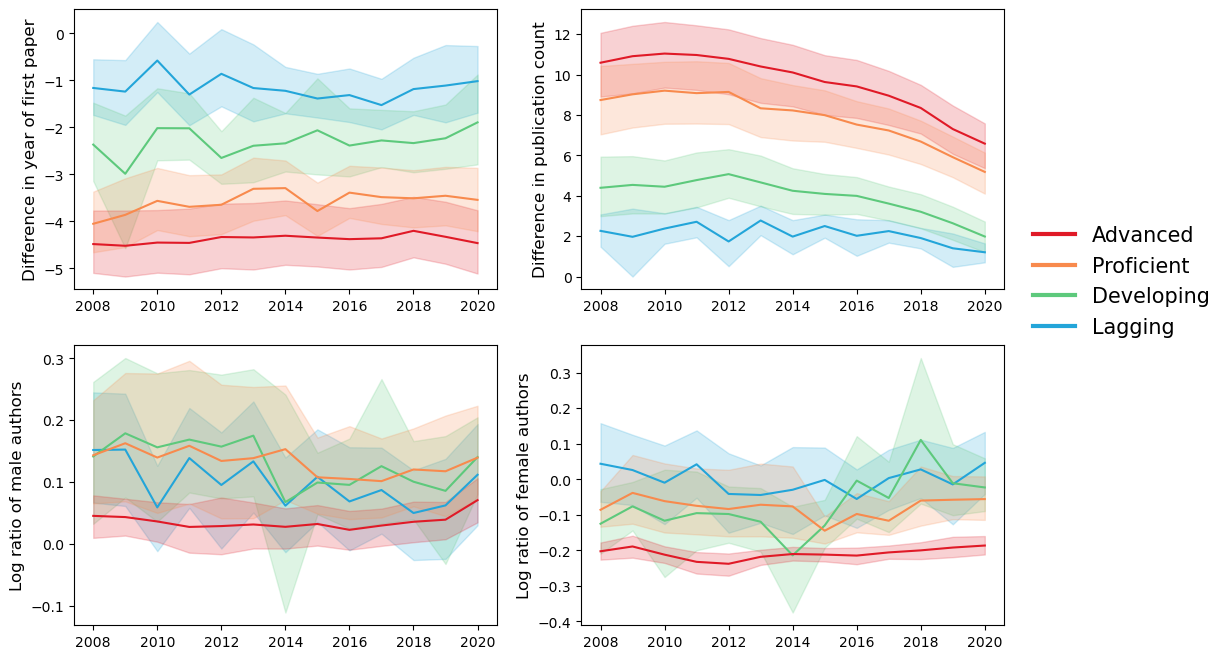

In [27]:
fig,ax=plt.subplots(nrows=2,ncols=2,figsize=(12,8))
ax0=plot(agg_df,'year_diff',ax[0][0],'Difference in year of first paper')
ax1=plot(agg_df,'npub_diff',ax[0][1],'Difference in publication count')
ax2=plot(agg_df,'male_diff',ax[1][0],'Log ratio of male authors')
ax3=plot(agg_df,'female_diff',ax[1][1],'Log ratio of female authors')

colors = ['#E01A27', '#F88A4D', '#5DC97C','#23A5D9']
lines = [Line2D([0], [0], color=c, linewidth=3, linestyle='-') for c in colors]
labels = ['Advanced', 'Proficient', 'Developing','Lagging']
plt.legend(lines, labels,loc=[1.05,1],frameon=False,fontsize=15)
plt.savefig(plot_path,bbox_inches='tight')

In [30]:
agg_df[(agg_df.ST=='Advanced')&(agg_df['year_']==2018)]

,cntry_,year_,yfp_raw,yfp_sample,npub_raw,npub_sample,male_raw,male_sample,female_raw,female_sample,year_diff,npub_diff,male_diff,female_diff,Code,ST
90,AUS,2018,2011.0,2016.0,15.0,4.00,21343.0,18137.1,13301.0,17373.5,-5.0,11.00,0.162764,-0.267107,AUS,Advanced
103,AUT,2018,2011.0,2015.0,12.0,4.00,7368.0,7221.3,4165.0,4696.3,-4.0,8.00,0.020111,-0.120059,AUT,Advanced
135,BEL,2018,2011.0,2015.5,13.0,4.10,8912.0,8874.4,5848.0,6862.1,-4.5,8.90,0.004228,-0.159914,BEL,Advanced
359,CAN,2018,2011.0,2016.0,11.0,3.20,25051.0,22592.2,15162.0,19067.7,-5.0,7.80,0.103309,-0.229204,CAN,Advanced
372,CHE,2018,2012.0,2015.8,12.0,4.00,14124.0,14261.9,7758.0,9425.2,-3.8,8.00,-0.009716,-0.194662,CHE,Advanced
524,DEU,2018,2012.0,2016.0,12.0,4.00,48540.0,49153.7,25452.0,31656.3,-4.0,8.00,-0.012564,-0.218143,DEU,Advanced
550,DNK,2018,2011.0,2015.0,14.0,4.30,6977.0,5995.5,4596.0,5327.0,-4.0,9.70,0.151610,-0.147602,DNK,Advanced
662,FIN,2018,2009.0,2014.0,15.0,5.00,4339.0,4003.6,3476.0,4564.2,-5.0,10.00,0.080450,-0.272361,FIN,Advanced
688,FRA,2018,2008.0,2014.0,16.0,5.00,30935.0,29908.8,20444.0,24516.3,-6.0,11.00,0.033735,-0.181649,FRA,Advanced
719,GBR,2018,2011.0,2016.0,12.0,3.10,48883.0,46302.8,29084.0,35245.4,-5.0,8.90,0.054227,-0.192147,GBR,Advanced


In [32]:
agg_df[(agg_df.ST=='Developing')&(agg_df['year_']==2018)]

,cntry_,year_,yfp_raw,yfp_sample,npub_raw,npub_sample,male_raw,male_sample,female_raw,female_sample,year_diff,npub_diff,male_diff,female_diff,Code,ST
63,ARG,2018,2009.0,2013.10,11.0,5.00,3512.0,2989.2,3401.0,4057.9,-4.10,6.00,0.161180,-0.176596,ARG,Developing
76,ARM,2018,2010.0,2011.60,8.0,5.10,110.0,67.7,86.0,61.8,-1.60,2.90,0.485394,0.330444,ARM,Developing
148,BEN,2018,2015.0,2018.00,5.0,2.00,224.0,178.0,56.0,55.1,-3.00,3.00,0.229863,0.016202,BEN,Developing
269,BOL,2018,2017.0,2018.00,2.0,1.00,170.0,151.5,98.0,68.2,-1.00,1.00,0.115213,0.362523,BOL,Developing
385,CHL,2018,2012.0,2016.40,9.0,3.00,4407.0,4249.0,2178.0,2849.3,-4.40,6.00,0.036511,-0.268666,CHL,Developing
449,COL,2018,2015.0,2018.00,4.0,2.00,2482.0,2357.5,1635.0,1767.3,-3.00,2.00,0.051463,-0.077810,COL,Developing
464,CRI,2018,2015.0,2017.50,4.0,2.00,323.0,285.0,201.0,233.0,-2.50,2.00,0.125163,-0.147734,CRI,Developing
599,EGY,2018,2014.0,2016.65,7.0,3.00,3416.0,2774.2,1568.0,2023.7,-2.65,4.00,0.208108,-0.255127,EGY,Developing
902,IDN,2018,2016.0,2018.00,3.0,1.50,987.0,750.9,621.0,507.3,-2.00,1.50,0.273398,0.202229,IDN,Developing
941,IRN,2018,2014.0,2017.00,9.0,3.00,9651.0,8466.0,3920.0,4783.7,-3.00,6.00,0.131003,-0.199123,IRN,Developing


In [68]:
boot_df[(boot_df.year==2018)&(boot_df.cntry=='TWN')]

,cntry,year,source,yfp,npub,male,female
19481,TWN,2018,raw,2018.0,2.0,6500.0,4774.0
19482,TWN,2018,sample,2018.0,1.0,7476.0,6059.0
19483,TWN,2018,sample,2018.0,1.0,7431.0,6075.0
19484,TWN,2018,sample,2018.0,1.0,7502.0,6088.0
19485,TWN,2018,sample,2018.0,1.0,7473.0,5967.0
19486,TWN,2018,sample,2018.0,1.0,7487.0,6033.0
19487,TWN,2018,sample,2018.0,1.0,7491.0,6124.0
19488,TWN,2018,sample,2018.0,1.0,7510.0,6025.0
19489,TWN,2018,sample,2018.0,1.0,7420.0,6047.0
19490,TWN,2018,sample,2018.0,1.0,7485.0,6092.0


In [69]:
cntry='TWN'
year=2018
int_author=return_authors(author_int_info,cntry,year)
dom_author=return_authors(author_dome_info,cntry,year)

if len(dom_author)>0 and len(int_author)>0:

    yfp_raw,npub_raw,male_raw,female_raw=return_measurement(int_author)
    result.append([cntry,year,'raw',yfp_raw,npub_raw,male_raw,female_raw])

    sample_size=int_author.shape[0]
    for i in range(10):
        sample_df=return_sample(dom_author,sample_size)
        yfp_s,npub_s,male_s,female_s=return_measurement(sample_df)
        result.append([cntry,year,'sample',yfp_s,npub_s,male_s,female_s])
else:
    result.append([cntry,year,'invalid'])

In [78]:
int_author['gender'].value_counts()

gender
M      6500
unk    5307
F      4774
Name: count, dtype: int64

In [79]:
dom_author['gender'].value_counts()

gender
M      20591
F      16784
unk     8465
Name: count, dtype: int64

In [1]:
5307/(6500+5307+4774)

0.32006513479283516

In [2]:
8465/(8465+20591+16784)

0.18466404886561955

In [3]:
6500+5307+4774

16581